# Phân tích kết quả học tập

Notebook hợp nhất các phần đọc dữ liệu, làm sạch dữ liệu, thống kê, trực quan hóa và hồi quy tuyến tính trong dự án `DiemSoHocSinh`.

Dữ liệu gồm 40 hồ sơ mô phỏng, không đại diện cho học sinh thật. Các nhóm kết quả và mô hình chỉ phục vụ thực hành phân tích dữ liệu.

## 0. Cài đặt và nạp thư viện

In [8]:
import io
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split

print("đã nạp libraries")

đã nạp libraries


## 1. Đọc dữ liệu

Notebook ưu tiên đọc `data/data.csv` trong thư mục hiện tại hoặc thư mục con `DiemSoHocSinh/data`. Nếu không tìm thấy file, notebook dùng bản dữ liệu gốc được nhúng bên dưới để vẫn chạy độc lập.

In [9]:
from pathlib import Path

candidate_files = [
    Path("data/data.csv"),
    Path("DiemSoHocSinh/data/data.csv"),
    Path("../data/data.csv"),
]

data_file = next((path for path in candidate_files if path.exists()), None)

if data_file is not None:
    raw_data = pd.read_csv(data_file)
    print("Đã đọc dữ liệu từ:", data_file)
else:
    raw_data = pd.read_csv(io.StringIO('record_id,grade_level,math_score,literature_score,english_score,science_score,attendance_pct,study_hours_per_day,homework_completion_pct\r\nHS001,10,9.2,8.7,8.9,9.1,98,2.8,100\r\nHS002,11,8.4,8.1,7.9,8.6,95,2.2,92\r\nHS003,12,7.8,8.4,8.1,7.5,94,2.0,90\r\nHS004,10,6.2,6.8,5.9,6.5,90,1.4,78\r\nHS005,11,5.4,5.8,6.1,5.6,87,1.0,70\r\nHS006,12,4.2,5.1,4.8,4.6,82,0.7,58\r\nHS007,10,8.8,9.1,8.2,8.7,97,2.5,96\r\nHS008,11,6.9,7.4,7.1,6.6,92,1.7,84\r\nHS009,12,9.5,8.9,9.2,9.3,99,3.0,100\r\nHS010,10,3.8,4.6,4.2,4.0,76,0.5,45\r\nHS011,11,7.2,6.8,7.6,7.0,93,1.8,86\r\nHS012,12,5.9,6.2,5.5,6.4,88,1.2,72\r\nHS013,10,7.9,8.3,7.5,8.1,96,2.1,91\r\nHS014,11,4.8,4.3,5.2,4.9,80,0.8,55\r\nHS015,12,8.6,7.9,8.8,8.3,96,2.4,94\r\nHS016,10,5.8,5.4,6.2,5.7,89,1.1,68\r\nHS017,11,9.1,8.8,8.5,9.0,98,2.7,98\r\nHS018,12,6.4,7.0,6.1,6.8,91,1.5,80\r\nHS019,10,4.5,5.2,4.7,5.0,84,0.8,60\r\nHS020,11,7.6,7.2,8.0,7.4,94,2.0,89\r\nHS021,12,3.9,4.4,3.8,4.7,78,0.4,48\r\nHS022,10,8.1,7.8,8.4,7.9,95,2.3,93\r\nHS023,11,5.1,6.0,5.3,5.8,86,1.0,66\r\nHS024,12,7.0,7.6,6.8,7.3,92,1.7,83\r\nHS025,10,9.4,9.0,9.3,8.8,99,3.1,100\r\nHS026,11,6.1,5.7,6.5,6.0,89,1.3,75\r\nHS027,12,5.6,4.9,5.8,5.4,85,0.9,62\r\nHS028,10,7.4,8.0,7.2,7.7,94,1.9,88\r\nHS029,11,4.1,4.8,4.5,3.9,79,0.6,50\r\nHS030,12,8.9,9.2,8.6,9.0,98,2.8,97\r\nHS031,10,6.7,6.3,7.0,6.5,91,1.5,79\r\nHS032,11,8.0,7.5,8.2,7.8,96,2.2,92\r\nHS033,12,4.9,5.5,4.6,5.2,83,0.8,57\r\nHS034,10,5.2,5.9,5.0,5.6,87,1.0,65\r\nHS035,11,7.8,8.2,7.4,8.0,95,2.1,90\r\nHS036,12,6.0,6.5,5.8,6.3,90,1.4,77\r\nHS037,10,3.5,4.2,4.0,3.7,74,0.4,42\r\nHS038,11,9.3,8.6,9.0,9.4,99,3.0,99\r\nHS039,12,7.3,7.9,7.1,7.6,93,1.8,85\r\nHS040,10,5.7,6.1,5.4,5.9,88,1.2,73\r\n'))
    print("Đang dùng dữ liệu CSV được nhúng trong notebook.")

print("Số hồ sơ ban đầu:", len(raw_data))
display(raw_data.head())

Đã đọc dữ liệu từ: data\data.csv
Số hồ sơ ban đầu: 40


,record_id,grade_level,math_score,literature_score,english_score,science_score,attendance_pct,study_hours_per_day,homework_completion_pct
0,HS001,10,9.2,8.7,8.9,9.1,98,2.8,100
1,HS002,11,8.4,8.1,7.9,8.6,95,2.2,92
2,HS003,12,7.8,8.4,8.1,7.5,94,2.0,90
3,HS004,10,6.2,6.8,5.9,6.5,90,1.4,78
4,HS005,11,5.4,5.8,6.1,5.6,87,1.0,70


## 2. Làm sạch dữ liệu

- Loại bỏ hồ sơ trùng theo `record_id`.
- Chuyển các cột số về kiểu dữ liệu số.
- Điền giá trị thiếu bằng trung vị của từng cột.
- Tính điểm trung bình từ bốn môn.
- Tạo nhóm kết quả theo ngưỡng minh họa.

In [10]:
SUBJECT_COLUMNS = [
    "math_score",
    "literature_score",
    "english_score",
    "science_score",
]

def clean_data(data):
    data = data.drop_duplicates(subset="record_id").copy()

    number_columns = [
        "grade_level",
        *SUBJECT_COLUMNS,
        "attendance_pct",
        "study_hours_per_day",
        "homework_completion_pct",
    ]

    for column in number_columns:
        data[column] = pd.to_numeric(data[column], errors="coerce")
        data[column] = data[column].fillna(data[column].median())

    data["average_score"] = data[SUBJECT_COLUMNS].mean(axis=1).round(2)
    data["learning_support_group"] = pd.cut(
        data["average_score"],
        bins=[-float("inf"), 5, 8, float("inf")],
        labels=["Cần hỗ trợ", "Đang tiến bộ", "Vững kiến thức"],
        right=False,
    )
    return data

data = clean_data(raw_data)

print("Số hồ sơ sau làm sạch:", len(data))
print("Số giá trị còn thiếu:", data.isna().sum().sum())
display(data.head())

Số hồ sơ sau làm sạch: 40
Số giá trị còn thiếu: 0


,record_id,grade_level,math_score,literature_score,english_score,science_score,attendance_pct,study_hours_per_day,homework_completion_pct,average_score,learning_support_group
0,HS001,10,9.2,8.7,8.9,9.1,98,2.8,100,8.98,Vững kiến thức
1,HS002,11,8.4,8.1,7.9,8.6,95,2.2,92,8.25,Vững kiến thức
2,HS003,12,7.8,8.4,8.1,7.5,94,2.0,90,7.95,Đang tiến bộ
3,HS004,10,6.2,6.8,5.9,6.5,90,1.4,78,6.35,Đang tiến bộ
4,HS005,11,5.4,5.8,6.1,5.6,87,1.0,70,5.72,Đang tiến bộ


## 3. Thống kê cơ bản

Các bảng dưới đây mô tả điểm trung bình, phân bố nhóm kết quả, điểm theo môn, điểm theo khối lớp và các chỉ báo học tập.

In [11]:
print("Số hồ sơ:", len(data))
print("Điểm trung bình chung:", round(data["average_score"].mean(), 2))

print("\nSố hồ sơ theo nhóm kết quả:")
display(data["learning_support_group"].value_counts(sort=False))

print("\nTỷ lệ hồ sơ theo nhóm kết quả (%):")
display((data["learning_support_group"].value_counts(normalize=True, sort=False) * 100).round(2))

print("\nĐiểm trung bình theo môn:")
display(data[SUBJECT_COLUMNS].mean().round(2))

print("\nĐiểm trung bình theo khối:")
display(
    data.groupby("grade_level")["average_score"]
    .agg(["count", "mean", "median"])
    .round(2)
)

indicator_columns = [
    "attendance_pct",
    "study_hours_per_day",
    "homework_completion_pct",
]
print("\nTương quan với điểm trung bình:")
display(data[indicator_columns + ["average_score"]].corr().round(2))

Số hồ sơ: 40
Điểm trung bình chung: 6.76

Số hồ sơ theo nhóm kết quả:


learning_support_group
Cần hỗ trợ         7
Đang tiến bộ      23
Vững kiến thức    10
Name: count, dtype: int64


Tỷ lệ hồ sơ theo nhóm kết quả (%):


learning_support_group
Cần hỗ trợ        17.5
Đang tiến bộ      57.5
Vững kiến thức    25.0
Name: proportion, dtype: float64


Điểm trung bình theo môn:


math_score          6.70
literature_score    6.85
english_score       6.71
science_score       6.79
dtype: float64


Điểm trung bình theo khối:


,count,mean,median
grade_level,,,
10,14,6.66,6.48
11,13,6.93,7.15
12,13,6.71,6.58



Tương quan với điểm trung bình:


,attendance_pct,study_hours_per_day,homework_completion_pct,average_score
attendance_pct,1.00,0.95,0.99,0.97
study_hours_per_day,0.95,1.00,0.96,0.99
homework_completion_pct,0.99,0.96,1.00,0.98
average_score,0.97,0.99,0.98,1.00


## 4. Trực quan hóa dữ liệu

Biểu đồ thể hiện phân bố điểm trung bình, điểm trung bình theo môn, mối liên hệ giữa thời gian tự học và điểm trung bình, cùng điểm trung bình theo nhóm mô tả.

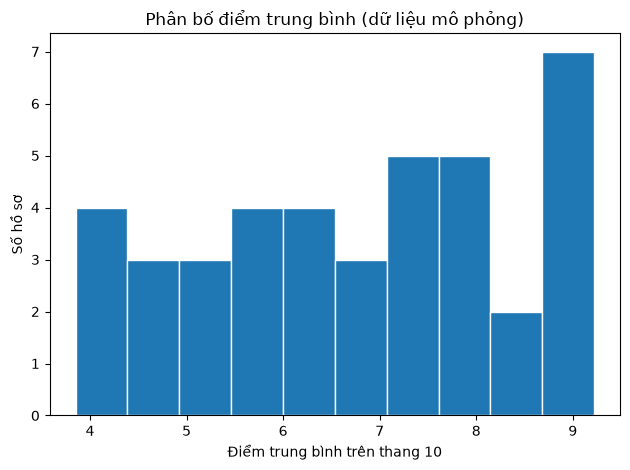

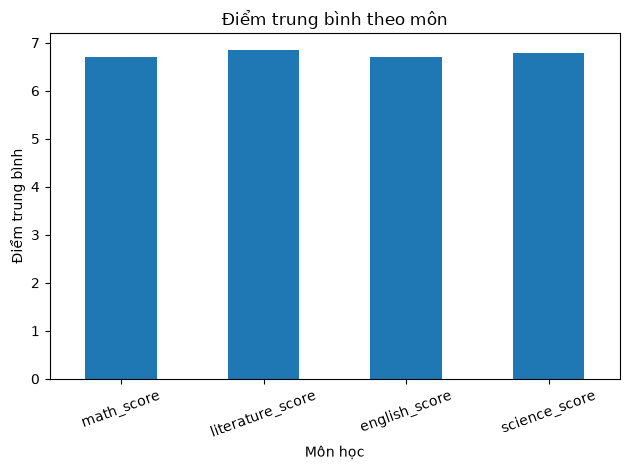

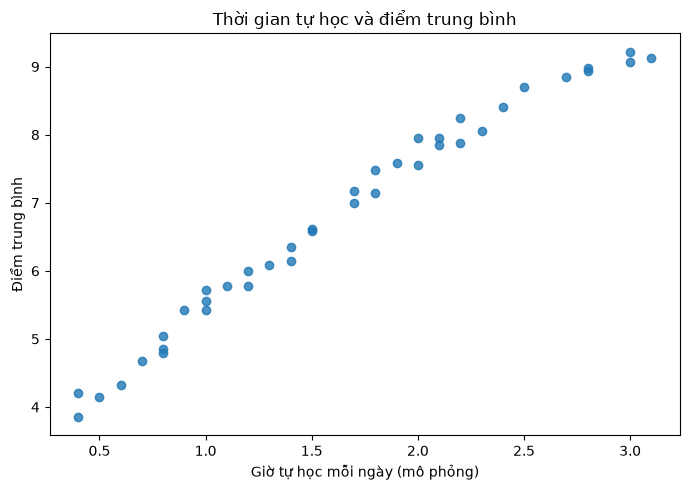

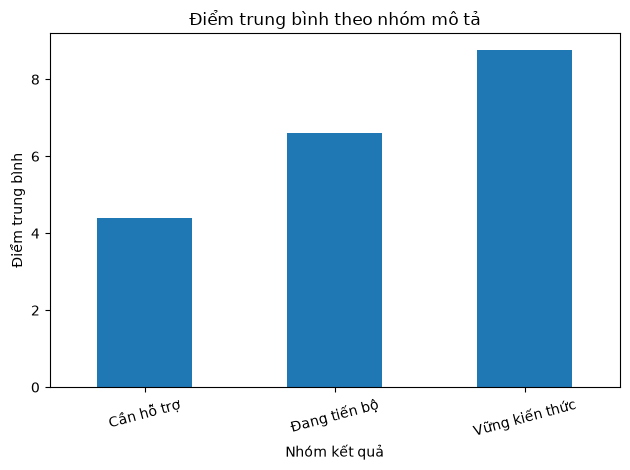

In [12]:
data["average_score"].plot(
    kind="hist", bins=10, edgecolor="white"
)
plt.title("Phân bố điểm trung bình (dữ liệu mô phỏng)")
plt.xlabel("Điểm trung bình trên thang 10")
plt.ylabel("Số hồ sơ")
plt.tight_layout()
plt.show()

data[SUBJECT_COLUMNS].mean().plot(kind="bar")
plt.title("Điểm trung bình theo môn")
plt.xlabel("Môn học")
plt.ylabel("Điểm trung bình")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
plt.scatter(
    data["study_hours_per_day"],
    data["average_score"],
    alpha=0.8,
)
plt.title("Thời gian tự học và điểm trung bình")
plt.xlabel("Giờ tự học mỗi ngày (mô phỏng)")
plt.ylabel("Điểm trung bình")
plt.tight_layout()
plt.show()

data.groupby("learning_support_group", observed=False)["average_score"].mean().plot(kind="bar")
plt.title("Điểm trung bình theo nhóm mô tả")
plt.xlabel("Nhóm kết quả")
plt.ylabel("Điểm trung bình")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 5. Mô hình hồi quy tuyến tính

Mô hình minh họa dự đoán điểm trung bình từ khối lớp, tỷ lệ tham dự, thời gian tự học và tỷ lệ hoàn thành bài tập. Tập kiểm tra chiếm 20% dữ liệu.

In [13]:
features = [
    "grade_level",
    "attendance_pct",
    "study_hours_per_day",
    "homework_completion_pct",
]

X = data[features]
y = data["average_score"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)
predictions = model.predict(X_test)

r2 = r2_score(y_test, predictions)
mae = mean_absolute_error(y_test, predictions)

print("R²:", round(r2, 2))
print("MAE (điểm trên thang 10):", round(mae, 2))

comparison = pd.DataFrame({
    "Điểm thực tế": y_test,
    "Điểm dự đoán": predictions,
})
display(comparison.head(10))

R²: 0.98
MAE (điểm trên thang 10): 0.15


,Điểm thực tế,Điểm dự đoán
19,7.55,7.631398
16,8.85,8.819889
15,5.78,5.511163
26,5.43,5.216999
4,5.72,5.643786
12,7.95,7.722539
37,9.07,9.199339
27,7.58,7.394910


## 6. Lưu dữ liệu đã làm sạch

Nếu thư mục `data` tồn tại, notebook lưu kết quả vào `data/cleaned_data.csv`. Nếu không, file được lưu tại thư mục hiện tại.

In [14]:
output_dir = Path("data")
if not output_dir.exists() and Path("DiemSoHocSinh/data").exists():
    output_dir = Path("DiemSoHocSinh/data")
output_dir.mkdir(parents=True, exist_ok=True)

clean_file = output_dir / "cleaned_data.csv"
data.to_csv(clean_file, index=False, encoding="utf-8-sig")
print("Đã lưu dữ liệu sạch tại:", clean_file.resolve())

Đã lưu dữ liệu sạch tại: C:\Users\HP\Documents\5.CSA03\buoi2\thumuc\DiemSoHocSinh\data\cleaned_data.csv


## 7. Câu hỏi phân tích và giới hạn

## Mục đích và lưu ý

Dự án minh họa cách làm sạch, thống kê, trực quan hóa và xây dựng mô hình hồi quy với điểm số giả lập. Dữ liệu có 40 hồ sơ tổng hợp, không thuộc về học sinh thật và không chứa tên, trường hoặc thông tin nhận dạng.

Các nhóm kết quả trong dự án nhằm mô tả dữ liệu và gợi ý chủ đề cần hỗ trợ, không phải đánh giá năng lực hay dán nhãn cá nhân. Ngưỡng phân loại là ví dụ minh họa, không thay thế quy định chính thức của trường. Nếu sử dụng dữ liệu thực, cần có sự cho phép phù hợp, giới hạn quyền truy cập, bảo vệ hồ sơ học tập và không công bố dữ liệu nhận dạng.

## Mô tả cột

- `record_id`: mã giả lập, không định danh người thật.
- `grade_level`: khối lớp (10, 11 hoặc 12).
- `math_score`, `literature_score`, `english_score`, `science_score`: điểm môn học trên thang 10.
- `attendance_pct`: tỷ lệ tham dự giả lập, phần trăm.
- `study_hours_per_day`: số giờ tự học trung bình mỗi ngày, giả lập.
- `homework_completion_pct`: tỷ lệ hoàn thành bài tập giả lập, phần trăm.
- `average_score`: điểm trung bình bốn môn, tính trong bước làm sạch.
- `learning_support_group`: nhóm mô tả kết quả: `Cần hỗ trợ` (<5), `Đang tiến bộ` (5 đến dưới 8), `Vững kiến thức` (từ 8 trở lên).

## Câu hỏi thống kê

1. Điểm trung bình chung của mẫu là bao nhiêu?
2. Tỷ lệ hồ sơ ở từng nhóm kết quả là bao nhiêu?
3. Môn nào có điểm trung bình cao nhất/thấp nhất?
4. Điểm trung bình có khác nhau giữa các khối lớp không?
5. Mức độ tham dự, tự học và hoàn thành bài tập liên hệ thế nào với điểm trung bình?
6. Các hồ sơ thuộc nhóm cần hỗ trợ có điểm môn nào thấp hơn tương đối?

## Câu hỏi thảo luận và giới hạn

1. Ngoài điểm số, bối cảnh nào cần tìm hiểu trước khi đề xuất hỗ trợ học tập?
2. Giáo viên có thể dùng kết quả tổng hợp để điều chỉnh bài giảng ra sao mà không làm học sinh bị gắn nhãn?
3. Mẫu giả lập có thể khác dữ liệu trường/lớp thực tế như thế nào?
4. Vì sao hồi quy và tương quan không chứng minh việc học nhiều hơn là nguyên nhân duy nhất làm điểm tăng?

Dữ liệu được tạo cho mục đích học tập, không đại diện cho học sinh hay trường học cụ thể. Không dùng mô hình để xếp loại, kỷ luật, tuyển chọn hoặc đưa ra quyết định giáo dục về cá nhân. Kết quả phân tích chỉ nên dùng để thực hành thống kê và thảo luận hỗ trợ học tập một cách có trách nhiệm.

## 8. Diễn giải kết quả

- R² cho biết mức độ phù hợp của mô hình trên tập kiểm tra. Giá trị thấp hoặc âm vẫn có thể xuất hiện.
- MAE là sai lệch tuyệt đối trung bình giữa điểm dự đoán và điểm trong dữ liệu.
- Tương quan không chứng minh quan hệ nhân quả.
- Cỡ mẫu nhỏ và dữ liệu mô phỏng nên kết quả chỉ phục vụ thực hành.
- Không dùng mô hình để xếp loại, kỷ luật, tuyển chọn hoặc đưa ra quyết định giáo dục về cá nhân.

## Nguồn tham khảo

- [UCI Student Performance](https://archive.ics.uci.edu/dataset/320/student+performance)
- [pandas](https://pandas.pydata.org/docs/)
- [Matplotlib](https://matplotlib.org/stable/users/index.html)
- [scikit-learn: LinearRegression](https://scikit-learn.org/stable/modules/linear_model.html#ordinary-least-squares)
- [BachDepTrai](https://www.facebook.com/share/1K6MSS9jJ5/)